# RQ4 — Baseline Logistic Regression: Traditional vs Spark Benchmark

**Objective:** compare predictive quality and elapsed runtime of the original Pandas/Scikit-learn baseline and a Spark MLlib baseline on the same HMDA 2024 modeling population. Execute all cells in order on a fresh Colab CPU runtime. Pandas runs first; Spark runs second, never concurrently.

Both runs retain the 12 predictors, saved lender train/test split, five lender-grouped folds, unweighted L2 logistic regression, and training-only OOF F1 threshold optimization. The original sklearn preprocessor is shared deliberately: the Spark branch uses native Spark loading, partitioning, fitting and prediction, but fits/transforms that preprocessor on the driver and transfers sparse vectors to Spark. This is a **hybrid compatibility benchmark**, not a fully native Spark preprocessing benchmark. Transfer costs are measured explicitly and included in the total. Spark uses `regParam=1/n_fit` to match sklearn's C=1 objective (unweighted mean logistic loss). Optimizers and stopping criteria can still differ.

Timing covers loading, split, each CV fold, preprocessing, transfer/materialization, model fitting, inference, evaluation and threshold selection. Startup and cleanup are separately reported. Common plotting/export is excluded. Run order and filesystem caches can affect timing; repeat in a fresh session with reversed order for stronger conclusions. No model tuning is performed.

## BM0. Environment and shared configuration
Use the same Drive artifacts as RQ4_Logistic_Regression. Install PySpark only if missing. Installation and Drive mount are excluded from both runtime totals.

In [ ]:
import importlib.util, sys, subprocess
if importlib.util.find_spec("pyspark") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "pyspark==3.5.5"])
import pyspark
print("PySpark version:", pyspark.__version__)

PySpark version: 4.0.5


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, gc, time, json, warnings, tempfile, shutil, platform
from contextlib import contextmanager
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import joblib
import scipy.sparse as sparse
import sklearn
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_curve, precision_recall_curve
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path('/content/drive/MyDrive/hmda')
SETUP = BASE / 'rq4_setup'
OUT = BASE / 'rq4_baseline_benchmark'
OUT.mkdir(parents=True, exist_ok=True)
with open(SETUP / 'master_modeling_config.json') as f:
    cfg = json.load(f)
a = cfg['shared_artifacts']
f = cfg['configurations']['feature_selection']
DATA_PATH = cfg['data_path']
FEATURES = f['features']; NUM = f['numeric_features']; CAT = f['categorical_features']
TARGET = f['target']; GROUP = f['group']; N_SPLITS = f['n_splits']
SEED = cfg['random_state']
THRESHOLD = cfg['configurations']['evaluation']['threshold_selection']['default_threshold']
COLS = FEATURES + [TARGET, GROUP]
assert len(FEATURES) == 12 and N_SPLITS == 5
sys.path.insert(0, str(SETUP))
from evaluation_utils import evaluate_predictions, optimize_f1_threshold
preprocessor = joblib.load(SETUP / a['lr_preprocessor'])
CPU = min(4, len(os.sched_getaffinity(0))) if hasattr(os, 'sched_getaffinity') else min(4, os.cpu_count() or 1)
SPARK_DRIVER_MEMORY = '4g'  # Adjust only if runtime RAM permits; record any change.
RUN_ORDER = ['Pandas', 'Spark']  # For a repeat on a fresh runtime, reverse this list.
LR_PARAMS = dict(penalty='l2', C=1.0, class_weight=None, solver='lbfgs', max_iter=500, tol=1e-4, random_state=SEED)
print('Data:', DATA_PATH, '| CPU limit:', CPU, '| sklearn:', sklearn.__version__)
print('Preprocessor:', preprocessor)

Mounted at /content/drive
Data: /content/drive/MyDrive/hmda/clean_pandas/S1_orig_denied | CPU limit: 2 | sklearn: 1.6.1
Preprocessor: ColumnTransformer(sparse_threshold=1.0,
                  transformers=[('numeric_identity',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['log_income', 'log_loan_amount',
                                  'combined_loan_to_value_ratio']),
                                ('numeric_log',
                                 Pipeline(steps=[('log_transform',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),...
                                                                           'provided',
          

## BM1. Shared helpers and measurement contract
Each timer records wall-clock seconds. Spark actions are forced before a stage ends; sparse conversions and driver collection are not hidden inside training. Both branches use the original evaluation utilities, with positive class = denial. CV predictions are pooled before threshold selection.

In [ ]:
timings = []; metrics_rows = []; threshold_rows = []; partition_rows = []; curves = {}; fit_rows = []; totals = []
@contextmanager
def timed(engine, phase, task, fold=0):
    start = time.perf_counter()
    try:
        yield
    finally:
        sec = time.perf_counter() - start
        timings.append(dict(engine=engine, phase=phase, fold=fold, task=task, seconds=sec))
        print(f'{engine:6} | {phase:8} | fold={fold} | {task:29} | {sec:,.2f}s', flush=True)

def read_splits():
    p = pd.read_csv(SETUP / a['lender_split'], dtype={GROUP: str})
    v = pd.read_csv(SETUP / a['cv_fold_assignment'], dtype={GROUP: str})
    assert p[GROUP].is_unique and v[GROUP].is_unique
    return p, v

def normalize(pdf):
    for col in NUM: pdf[col] = pdf[col].astype('float32')
    for col in CAT + [GROUP]: pdf[col] = pdf[col].astype('category')
    pdf[TARGET] = pdf[TARGET].astype('int8')
    return pdf

def record_partition(engine, phase, fold, yfit, yval):
    for split, y in [('fit', yfit), ('evaluation', yval)]:
        assert set(np.unique(y)) == {0, 1}
        partition_rows.append(dict(engine=engine, phase=phase, fold=fold, split=split, n=len(y), denied=int(y.sum())))

def metrics(engine, phase, fold, y, prob, kind, threshold):
    assert len(y) == len(prob) and np.isfinite(prob).all()
    m = evaluate_predictions(y, prob, threshold=threshold)
    metrics_rows.append(dict(engine=engine, phase=phase, fold=fold, threshold_type=kind, **m))
    return m

def encode(fit, val):
    p = clone(preprocessor)
    xf = sparse.csr_matrix(p.fit_transform(fit[FEATURES]), dtype=np.float64)
    xv = sparse.csr_matrix(p.transform(val[FEATURES]), dtype=np.float64)
    return xf, xv

def record_curves(engine, y, prob):
    fpr, tpr, _ = roc_curve(y, prob)
    precision, recall, _ = precision_recall_curve(y, prob)
    curves[engine] = (fpr, tpr, recall, precision)

def choose_threshold(engine, ys, ps):
    with timed(engine, 'OOF', 'Threshold selection'):
        y = np.concatenate(ys); prob = np.concatenate(ps)
        result = optimize_f1_threshold(y, prob)
        threshold = float(result['optimal_threshold'])
        threshold_rows.append(dict(engine=engine, **result))
    with timed(engine, 'OOF', 'Evaluation'):
        metrics(engine, 'OOF', 0, y, prob, 'Default', THRESHOLD)
        metrics(engine, 'OOF', 0, y, prob, 'Optimized', threshold)
    return threshold

## BM2. Pandas + Scikit-learn pipeline
Load the original Parquet using PyArrow; validate restored indices and CV assignments. Fit the shared preprocessor separately inside every training fold and once on the full training partition. Test preprocessing is measured separately from prediction through the shared feature-encoding stage.

In [ ]:
def run_pandas():
    e = 'Pandas'; wall = time.perf_counter()
    with threadpool_limits(limits=CPU):
        with timed(e, 'Setup', 'Data loading'):
            table = pq.read_table(DATA_PATH, columns=COLS)
            for i, field in enumerate(table.schema):
                if pa.types.is_dictionary(field.type):
                    table = table.set_column(i, field.name, table.column(i).cast(field.type.value_type))
            df = normalize(table.to_pandas(strings_to_categorical=True)); del table
        with timed(e, 'Setup', 'Partition assignment'):
            p, v = read_splits()
            part = df[GROUP].map(p.set_index(GROUP)['partition'])
            assert part.notna().all()
            tr = np.flatnonzero(part.eq('train').to_numpy()); te = np.flatnonzero(part.eq('test').to_numpy())
            with np.load(SETUP / a['train_test_indices']) as saved:
                assert np.array_equal(tr, saved['train_idx']) and np.array_equal(te, saved['test_idx'])
            train = df.iloc[tr].reset_index(drop=True); test = df.iloc[te].reset_index(drop=True)
            folds = train[GROUP].map(v.set_index(GROUP)['validation_fold']).to_numpy(dtype=np.int8)
            assert np.array_equal(folds, np.load(SETUP / a['cv_fold_array']))
            assert len(df) == cfg['population']['total_applications']
            del df, part, tr, te; gc.collect()
        ys, ps = [], []
        def one(phase, fold):
            with timed(e, phase, 'Select fit/evaluation rows', fold):
                fit = train.loc[folds != fold] if fold else train
                val = train.loc[folds == fold] if fold else test
                yf = fit[TARGET].to_numpy(); yv = val[TARGET].to_numpy()
                record_partition(e, phase, fold, yf, yv)
            with timed(e, phase, 'Feature preprocessing', fold):
                xf, xv = encode(fit, val)
            del fit, val
            with timed(e, phase, 'Model training', fold):
                model = LogisticRegression(**LR_PARAMS)
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter('always', ConvergenceWarning)
                    model.fit(xf, yf)
                converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
                fit_rows.append(dict(engine=e, phase=phase, fold=fold, encoded_features=xf.shape[1], iterations=int(model.n_iter_.max()), convergence_status='Converged' if converged else 'Warning'))
            with timed(e, phase, 'Prediction', fold):
                prob = model.predict_proba(xv)[:, 1]
            with timed(e, phase, 'Resource cleanup', fold):
                del xf, xv, model, yf; gc.collect()
            return yv, prob
        for fold in range(1, N_SPLITS+1):
            y, prob = one('CV', fold)
            with timed(e, 'CV', 'Evaluation', fold):
                metrics(e, 'CV', fold, y, prob, 'Default', THRESHOLD)
                ys.append(y); ps.append(prob)
        threshold = choose_threshold(e, ys, ps); del ys, ps
        y, prob = one('Test', 0)
        with timed(e, 'Test', 'Evaluation'):
            metrics(e, 'Test', 0, y, prob, 'Default', THRESHOLD)
            metrics(e, 'Test', 0, y, prob, 'Optimized', threshold)
            record_curves(e, y, prob)
        with timed(e, 'Setup', 'Resource cleanup'):
            del train, test, folds, y, prob; gc.collect()
    totals.append(dict(engine=e, wall_seconds=time.perf_counter()-wall))

## BM3. PySpark MLlib pipeline
Spark reads and joins lender partitions natively. Each fold is collected to the driver for exact reuse of the saved sklearn preprocessing specification; sparse transformed data is staged as local Parquet and loaded as Spark vectors. The transfer is part of the Spark runtime, not an unreported setup cost. Training and inference use Spark MLlib. The Spark cache uses memory/disk storage, and actions force materialization. Spark startup/shutdown are measured independently.

In [ ]:
def stage_sparse(matrix, y, path):
    # Write CSR rows in bounded batches; avoids creating a dense matrix.
    schema = pa.schema([('indices', pa.list_(pa.int32())), ('values', pa.list_(pa.float64())), ('label', pa.float64())])
    with pq.ParquetWriter(str(path), schema, compression='snappy') as writer:
        for lo in range(0, matrix.shape[0], 100_000):
            hi = min(lo+100_000, matrix.shape[0]); m = matrix[lo:hi]
            off = pa.array(m.indptr.astype(np.int32))
            writer.write_table(pa.Table.from_arrays([
                pa.ListArray.from_arrays(off, pa.array(m.indices.astype(np.int32, copy=False))),
                pa.ListArray.from_arrays(off, pa.array(m.data)),
                pa.array(y[lo:hi].astype(np.float64))], schema=schema))

def run_spark():
    from pyspark.sql import SparkSession, functions as F
    from pyspark import StorageLevel
    from pyspark.ml.linalg import Vectors, VectorUDT
    from pyspark.ml.classification import LogisticRegression as SparkLR
    from pyspark.ml.functions import vector_to_array
    e = 'Spark'; wall = time.perf_counter()
    spark = None; root = tempfile.mkdtemp(prefix='hmda_bench_')
    try:
        with timed(e, 'Setup', 'Engine startup'):
            spark = (SparkSession.builder.master(f'local[{CPU}]').appName('HMDA_Baseline_Benchmark')
                     .config('spark.driver.memory', SPARK_DRIVER_MEMORY)
                     .config('spark.driver.maxResultSize', '2g')
                     .config('spark.sql.shuffle.partitions', str(max(8, CPU*4)))
                     .config('spark.sql.execution.arrow.pyspark.enabled', 'true')
                     .config('spark.local.dir', root+'/shuffle').getOrCreate())
            spark.sparkContext.setLogLevel('WARN'); spark.range(1).count()
        with timed(e, 'Setup', 'Data loading'):
            raw = spark.read.parquet(str(DATA_PATH)).select(*COLS).persist(StorageLevel.MEMORY_AND_DISK)
            assert raw.count() == cfg['population']['total_applications']
        with timed(e, 'Setup', 'Partition assignment'):
            p = spark.read.option('header', True).csv(str(SETUP / a['lender_split'])).select(GROUP, 'partition')
            v = spark.read.option('header', True).csv(str(SETUP / a['cv_fold_assignment'])).select(GROUP, F.col('validation_fold').cast('int').alias('fold'))
            assert p.count() == p.select(GROUP).distinct().count()
            assert v.count() == v.select(GROUP).distinct().count()
            data = raw.join(F.broadcast(p), GROUP, 'left').join(F.broadcast(v), GROUP, 'left').persist(StorageLevel.MEMORY_AND_DISK)
            assert data.count() == cfg['population']['total_applications']
            assert data.filter(F.col('partition').isNull() | ~F.col('partition').isin('train','test') | ((F.col('partition')=='train') & (F.col('fold').isNull() | ~F.col('fold').between(1, N_SPLITS)))).count() == 0
            counts = {r['partition']: r['count'] for r in data.groupBy('partition').count().collect()}
            assert counts['train'] == cfg['population']['training_applications'] and counts['test'] == cfg['population']['test_applications']
            raw.unpersist(blocking=True)
        ys, ps = [], []
        def one(phase, fold):
            with timed(e, phase, 'Select fit/evaluation rows', fold):
                train = data.filter(F.col('partition')=='train')
                fit = train.filter(F.col('fold')!=fold) if fold else train
                val = train.filter(F.col('fold')==fold) if fold else data.filter(F.col('partition')=='test')
                # Collection is measured separately, including actual filter execution.
            with timed(e, phase, 'Driver collection', fold):
                fit_pdf = normalize(fit.select(*COLS).toPandas())
                val_pdf = normalize(val.select(*COLS).toPandas())
                yf = fit_pdf[TARGET].to_numpy(); yv = val_pdf[TARGET].to_numpy()
                record_partition(e, phase, fold, yf, yv)
            with timed(e, phase, 'Feature preprocessing', fold):
                with threadpool_limits(limits=CPU):
                    xf, xv = encode(fit_pdf, val_pdf)
            del fit_pdf, val_pdf; gc.collect()
            d = xf.shape[1]; n_fit = len(yf)
            with timed(e, phase, 'Spark vector transfer', fold):
                fp = Path(root)/'fit.parquet'; vp = Path(root)/'val.parquet'
                stage_sparse(xf, yf, fp); stage_sparse(xv, yv, vp)
                @F.udf(VectorUDT())
                def make_vector(indices, values):
                    return Vectors.sparse(d, indices, values)
                def load_vectors(path):
                    return (spark.read.parquet(str(path)).select('label', make_vector('indices','values').alias('features'))
                            .repartition(max(8, CPU*4)).persist(StorageLevel.MEMORY_AND_DISK))
                sf = load_vectors(fp); sv = load_vectors(vp)
                assert sf.count() == n_fit and sv.count() == len(yv)
            del xf, xv, yf, yv; gc.collect()
            with timed(e, phase, 'Model training', fold):
                lr = SparkLR(featuresCol='features', labelCol='label', family='binomial', regParam=1.0/n_fit,
                             elasticNetParam=0.0, standardization=False, fitIntercept=True, maxIter=500, tol=1e-4)
                model = lr.fit(sf)
                iterations = model.summary.totalIterations
                fit_rows.append(dict(engine=e, phase=phase, fold=fold, encoded_features=d, iterations=int(iterations), convergence_status='Iteration cap reached' if iterations>=500 else 'Stopped before cap'))
            with timed(e, phase, 'Prediction', fold):
                # Collect labels and probabilities together; Spark order is not assumed.
                pred = model.transform(sv).select('label', vector_to_array('probability')[1].alias('prob')).toPandas()
                y = pred['label'].to_numpy(dtype=np.int8); prob = pred['prob'].to_numpy(dtype=np.float64)
            with timed(e, phase, 'Resource cleanup', fold):
                sf.unpersist(blocking=True); sv.unpersist(blocking=True)
                del sf, sv, model, pred; fp.unlink(); vp.unlink(); gc.collect()
            return y, prob
        for fold in range(1, N_SPLITS+1):
            y, prob = one('CV', fold)
            with timed(e, 'CV', 'Evaluation', fold):
                metrics(e, 'CV', fold, y, prob, 'Default', THRESHOLD)
                ys.append(y); ps.append(prob)
        threshold = choose_threshold(e, ys, ps); del ys, ps
        y, prob = one('Test', 0)
        with timed(e, 'Test', 'Evaluation'):
            metrics(e, 'Test', 0, y, prob, 'Default', THRESHOLD)
            metrics(e, 'Test', 0, y, prob, 'Optimized', threshold)
            record_curves(e, y, prob)
        with timed(e, 'Setup', 'Resource cleanup'):
            data.unpersist(blocking=True); del data, y, prob; gc.collect()
    finally:
        with timed(e, 'Setup', 'Engine shutdown'):
            if spark is not None: spark.stop()
            shutil.rmtree(root, ignore_errors=True)
    totals.append(dict(engine=e, wall_seconds=time.perf_counter()-wall))

## BM4. Execute sequentially
Do not rerun one engine selectively when comparing cold-session wall times. If a run fails, partial timing is exported and the error is recorded; incomplete runs are not assigned a speedup or presented as successful benchmarks.

In [ ]:
status = []
for engine in RUN_ORDER:
    print('\n' + '='*70 + f'\nRUNNING {engine}\n' + '='*70)
    try:
        (run_pandas if engine=='Pandas' else run_spark)()
        status.append(dict(engine=engine, status='Completed', error=''))
    except Exception as exc:
        status.append(dict(engine=engine, status='Failed', error=repr(exc)))
        print('FAILED:', repr(exc))
    finally:
        gc.collect()
        pd.DataFrame(timings).to_csv(OUT/'timing_detail.csv', index=False)
        pd.DataFrame(metrics_rows).to_csv(OUT/'metrics_detail.csv', index=False)
        pd.DataFrame(status).to_csv(OUT/'run_status.csv', index=False)
display(pd.DataFrame(status))


RUNNING Pandas
Pandas | Setup    | fold=0 | Data loading                  | 26.29s
Pandas | Setup    | fold=0 | Partition assignment          | 4.63s
Pandas | CV       | fold=1 | Select fit/evaluation rows    | 0.37s
Pandas | CV       | fold=1 | Feature preprocessing         | 24.42s
Pandas | CV       | fold=1 | Model training                | 27.55s
Pandas | CV       | fold=1 | Prediction                    | 0.07s
Pandas | CV       | fold=1 | Resource cleanup              | 0.15s
Pandas | CV       | fold=1 | Evaluation                    | 2.18s
Pandas | CV       | fold=2 | Select fit/evaluation rows    | 0.37s
Pandas | CV       | fold=2 | Feature preprocessing         | 22.09s
Pandas | CV       | fold=2 | Model training                | 32.40s
Pandas | CV       | fold=2 | Prediction                    | 0.08s
Pandas | CV       | fold=2 | Resource cleanup              | 0.16s
Pandas | CV       | fold=2 | Evaluation                    | 2.29s
Pandas | CV       | fold=3 | Select fit/e

,engine,status,error
0,Pandas,Completed,
1,Spark,Completed,


## BM5. Runtime comparison — individual tasks before totals
Speedup = Pandas seconds / Spark seconds. Values above 1 favor Spark. A missing stage means it is not applicable to that implementation, not zero-cost. Spark row selection is lazy; for a comparable selection subtotal, combine its selection and driver collection. The summed task time and actual wall time are both reported; the difference is uninstrumented overhead. Do not compare partial totals as if the run succeeded.

In [ ]:
td = pd.DataFrame(timings)
complete = {r['engine'] for r in status if r['status']=='Completed'}
if not td.empty:
    detail = td.pivot_table(index=['phase','fold','task'], columns='engine', values='seconds', aggfunc='sum').reindex(columns=['Pandas','Spark'])
    detail['speedup_pandas_over_spark'] = detail['Pandas']/detail['Spark'].replace(0,np.nan) if len(complete)==2 else np.nan
    display(detail.round(3)); detail.to_csv(OUT/'runtime_by_fold_task.csv')
    phase_task = td.pivot_table(index=['phase','task'],columns='engine',values='seconds',aggfunc='sum').reindex(columns=['Pandas','Spark'])
    phase_task['speedup_pandas_over_spark'] = phase_task['Pandas']/phase_task['Spark'].replace(0,np.nan) if len(complete)==2 else np.nan
    display(phase_task.round(3)); phase_task.to_csv(OUT/'runtime_by_phase_task.csv')
    if len(complete)==2:
        # Harmonize selection boundaries and group implementation-specific costs.
        t = td.copy(); t['comparable_task'] = t.task.replace({'Select fit/evaluation rows':'Row selection and collection','Driver collection':'Row selection and collection'})
        task = t.pivot_table(index='comparable_task', columns='engine', values='seconds', aggfunc='sum').reindex(columns=['Pandas','Spark'])
        task['speedup_pandas_over_spark'] = task['Pandas']/task['Spark'].replace(0,np.nan)
        display(task.round(3)); task.to_csv(OUT/'runtime_by_task.csv')
        phases = td.pivot_table(index='phase',columns='engine',values='seconds',aggfunc='sum').reindex(columns=['Pandas','Spark'])
        phases['speedup_pandas_over_spark'] = phases['Pandas']/phases['Spark']
        display(phases.round(3)); phases.to_csv(OUT/'runtime_by_phase.csv')
        total = pd.DataFrame(totals).set_index('engine').reindex(['Pandas','Spark'])
        total['sum_task_seconds'] = td.groupby('engine').seconds.sum()
        total['unallocated_seconds'] = total.wall_seconds-total.sum_task_seconds
        lifecycle = td[td.task.isin(['Engine startup','Engine shutdown'])].groupby('engine').seconds.sum()
        total['engine_lifecycle_seconds'] = lifecycle.reindex(total.index).fillna(0)
        total['wall_excluding_engine_lifecycle'] = total.wall_seconds-total.engine_lifecycle_seconds
        total['wall_minutes'] = total.wall_seconds/60
        display(total.round(3)); total.to_csv(OUT/'runtime_total.csv')
        print('End-to-end speedup:', round(total.loc['Pandas','wall_seconds']/total.loc['Spark','wall_seconds'],3))
        print('Speedup excluding engine lifecycle:', round(total.loc['Pandas','wall_excluding_engine_lifecycle']/total.loc['Spark','wall_excluding_engine_lifecycle'],3))

engine                                 Pandas    Spark  \
phase fold task                                          
CV    1    Driver collection              NaN   40.830   
           Evaluation                   2.181    2.348   
           Feature preprocessing       24.421   24.434   
           Model training              27.546   55.452   
           Prediction                   0.075    4.220   
           Resource cleanup             0.146    0.202   
           Select fit/evaluation rows   0.365    0.049   
           Spark vector transfer          NaN  300.858   
      2    Driver collection              NaN   36.206   
           Evaluation                   2.287    2.374   
           Feature preprocessing       22.094   25.222   
           Model training              32.404   48.946   
           Prediction                   0.080    2.418   
           Resource cleanup             0.158    0.216   
           Select fit/evaluation rows   0.370    0.085   
           Spark vector transfer          NaN  295.692   
      3    Driver collection              NaN   36.231   
           Evaluation                   1.655    1.686   
           Feature preprocessing       22.730   26.626   
           Model training              29.644   46.646   
           Prediction                   0.057    2.107   
           Resource cleanup             0.117    0.160   
           Select fit/evaluation rows   0.494    0.068   
           Spark vector transfer          NaN  289.030   
      4    Driver collection              NaN   34.741   
           Evaluation                   2.292    1.696   
           Feature preprocessing       22.699   29.804   
           Model training              22.994   47.319   
           Prediction                   0.057    1.942   
           Resource cleanup             0.118    0.160   
           Select fit/evaluation rows   0.360    0.031   
           Spark vector transfer          NaN  286.843   
      5    Driver collection              NaN   37.594   
           Evaluation                   1.663    1.715   
           Feature preprocessing       22.994   23.802   
           Model training              30.545   49.104   
           Prediction                   0.057    2.490   
           Resource cleanup             0.131    0.162   
           Select fit/evaluation rows   0.516    0.030   
           Spark vector transfer          NaN  294.127   
OOF   0    Evaluation                  20.369   20.987   
           Threshold selection          2.091    2.133   
Setup 0    Data loading                26.285   54.386   
           Engine shutdown                NaN    1.004   
           Engine startup                 NaN   18.734   
           Partition assignment         4.634   69.185   
           Resource cleanup             0.146    0.183   
Test  0    Driver collection              NaN   39.838   
           Evaluation                   7.224    7.627   
           Feature preprocessing       30.048   37.649   
           Model training              34.594   58.057   
           Prediction                   0.088    3.050   
           Resource cleanup             0.120    0.163   
           Select fit/evaluation rows   0.136    0.026   
           Spark vector transfer          NaN  391.927   

engine                                 speedup_pandas_over_spark  
phase fold task                                                   
CV    1    Driver collection                                 NaN  
           Evaluation                                      0.929  
           Feature preprocessing                           0.999  
           Model training                                  0.497  
           Prediction                                      0.018  
           Resource cleanup                                0.722  
           Select fit/evaluation rows                      7.419  
           Spark vector transfer                             NaN  
      2    Driver colle

engine                             Pandas     Spark  speedup_pandas_over_spark
phase task                                                                    
CV    Driver collection               NaN   185.602                        NaN
      Evaluation                   10.078     9.819                      1.026
      Feature preprocessing       114.939   129.887                      0.885
      Model training              143.135   247.468                      0.578
      Prediction                    0.326    13.177                      0.025
      Resource cleanup              0.670     0.900                      0.744
      Select fit/evaluation rows    2.105     0.263                      8.000
      Spark vector transfer           NaN  1466.549                        NaN
OOF   Evaluation                   20.369    20.987                      0.971
      Threshold selection           2.091     2.133                      0.980
Setup Data loading                 26.285    54.386                      0.483
      Engine shutdown                 NaN     1.004                        NaN
      Engine startup                  NaN    18.734                        NaN
      Partition assignment          4.634    69.185                      0.067
      Resource cleanup              0.146     0.183                      0.798
Test  Driver collection               NaN    39.838                        NaN
      Evaluation                    7.224     7.627                      0.947
      Feature preprocessing        30.048    37.649                      0.798
      Model training               34.594    58.057                      0.596
      Prediction                    0.088     3.050                      0.029
      Resource cleanup              0.120     0.163                      0.736
      Select fit/evaluation rows    0.136     0.026                      5.338
      Spark vector transfer           NaN   391.927                        NaN

engine,Pandas,Spark,speedup_pandas_over_spark
comparable_task,,,
Data loading,26.285,54.386,0.483
Engine shutdown,NaN,1.004,NaN
Engine startup,NaN,18.734,NaN
Evaluation,37.672,38.433,0.980
Feature preprocessing,144.986,167.536,0.865
Model training,177.729,305.525,0.582
Partition assignment,4.634,69.185,0.067
Prediction,0.414,16.227,0.025
Resource cleanup,0.936,1.246,0.751


engine,Pandas,Spark,speedup_pandas_over_spark
phase,,,
CV,271.252,2053.666,0.132
OOF,22.460,23.120,0.971
Setup,31.065,143.492,0.216
Test,72.211,538.336,0.134


,wall_seconds,sum_task_seconds,unallocated_seconds,engine_lifecycle_seconds,wall_excluding_engine_lifecycle,wall_minutes
engine,,,,,,
Pandas,397.070,396.987,0.083,0.000,397.070,6.618
Spark,2761.012,2758.614,2.398,19.737,2741.274,46.017


End-to-end speedup: 0.144
Speedup excluding engine lifecycle: 0.145


## BM6. Predictive quality comparison
Validate matching fold/test counts, positive counts and encoded dimensionality. Compare per-fold CV performance, pooled OOF performance, and held-out test results at both the shared default threshold and each model's independently optimized OOF threshold. Differences are Spark minus Pandas. Matching counts verify aggregate partition integrity; this notebook does not perform a row-level prediction join.

In [ ]:
m = pd.DataFrame(metrics_rows); partitions = pd.DataFrame(partition_rows); fits = pd.DataFrame(fit_rows)
partitions.to_csv(OUT/'partition_checks.csv',index=False); fits.to_csv(OUT/'fit_diagnostics.csv',index=False)
pd.DataFrame(threshold_rows).to_csv(OUT/'thresholds.csv',index=False)
if len(complete)==2:
    keys = ['phase','fold','split']; pp = partitions.pivot(index=keys,columns='engine',values=['n','denied'])
    assert (pp[('n','Pandas')]==pp[('n','Spark')]).all() and (pp[('denied','Pandas')]==pp[('denied','Spark')]).all(), 'Partition mismatch'
    dims = fits.pivot(index=['phase','fold'], columns='engine', values='encoded_features')
    assert (dims.Pandas==dims.Spark).all(), 'Encoded dimension mismatch'
    print('Partition counts, class counts and encoded dimensions: PASS')
    display(fits)
    scores = [k for k in ['threshold','roc_auc','average_precision','accuracy','precision','recall','f1','specificity','brier_score','true_negative','false_positive','false_negative','true_positive'] if k in m.columns]
    cv = m[m.phase=='CV'].groupby('engine')[scores].agg(['mean','std'])
    display(cv.round(6)); cv.to_csv(OUT/'cv_summary.csv')
    for phase in ['CV','OOF','Test']:
        subset = m[m.phase==phase]
        comparison = subset.melt(id_vars=['engine','fold','threshold_type'], value_vars=scores, var_name='metric').pivot(index=['fold','threshold_type','metric'],columns='engine',values='value').reindex(columns=['Pandas','Spark'])
        comparison['difference_spark_minus_pandas'] = comparison.Spark-comparison.Pandas
        display(comparison.round(6)); comparison.to_csv(OUT/f'{phase.lower()}_metric_comparison.csv')
else:
    print('Comparison not available: both engines must complete.')

Partition counts, class counts and encoded dimensions: PASS


,engine,phase,fold,encoded_features,iterations,convergence_status
0,Pandas,CV,1,88,57,Converged
1,Pandas,CV,2,88,69,Converged
2,Pandas,CV,3,88,62,Converged
3,Pandas,CV,4,88,50,Converged
4,Pandas,CV,5,88,66,Converged
5,Pandas,Test,0,88,60,Converged
6,Spark,CV,1,88,24,Stopped before cap
7,Spark,CV,2,88,23,Stopped before cap
8,Spark,CV,3,88,23,Stopped before cap
9,Spark,CV,4,88,24,Stopped before cap


threshold        roc_auc           average_precision            \
            mean  std      mean       std              mean       std   
engine                                                                  
Pandas       0.5  0.0  0.808738  0.027038          0.674263  0.047572   
Spark        0.5  0.0  0.808707  0.027011          0.674238  0.047588   

        accuracy           precision            ... brier_score            \
            mean       std      mean       std  ...        mean       std   
engine                                          ...                         
Pandas  0.818376  0.019740  0.765154  0.057106  ...    0.134179  0.013907   
Spark   0.818357  0.019735  0.764811  0.057497  ...    0.134204  0.013901   

       true_negative               false_positive              false_negative  \
                mean           std           mean          std           mean   
engine                                                                          
Pandas      899341.2  34801.812851        40335.6  7723.447307       188811.0   
Spark       899235.6  34719.272642        40441.2  7824.848701       188730.0   

                     true_positive                
                 std          mean           std  
engine                                            
Pandas  30706.895195      133166.8  17542.531166  
Spark   30752.792491      133247.8  17555.182303  

[2 rows x 26 columns]

engine                                        Pandas          Spark  \
fold threshold_type metric                                            
1    Default        accuracy                0.825238       0.825106   
                    average_precision       0.603658       0.603583   
                    brier_score             0.132438       0.132468   
                    f1                      0.496657       0.496530   
                    false_negative     170615.000000  170588.000000   
...                                              ...            ...   
5    Default        roc_auc                 0.848484       0.848452   
                    specificity             0.961074       0.961029   
                    threshold               0.500000       0.500000   
                    true_negative      885221.000000  885180.000000   
                    true_positive      155322.000000  155442.000000   

engine                                 difference_spark_minus_pandas  
fold threshold_type metric                                            
1    Default        accuracy                               -0.000132  
                    average_precision                      -0.000076  
                    brier_score                             0.000029  
                    f1                                     -0.000127  
                    false_negative                        -27.000000  
...                                                              ...  
5    Default        roc_auc                                -0.000033  
                    specificity                            -0.000045  
                    threshold                               0.000000  
                    true_negative                         -41.000000  
                    true_positive                         120.000000  

[65 rows x 3 columns]

engine                                       Pandas         Spark  \
fold threshold_type metric                                          
0    Default        accuracy           8.183760e-01  8.183570e-01   
                    average_precision  6.732040e-01  6.731490e-01   
                    brier_score        1.341790e-01  1.342040e-01   
                    f1                 5.375260e-01  5.376510e-01   
                    false_negative     9.440550e+05  9.436500e+05   
                    false_positive     2.016780e+05  2.022060e+05   
                    precision          7.675210e-01  7.671630e-01   
                    recall             4.135900e-01  4.138420e-01   
                    roc_auc            8.070660e-01  8.070280e-01   
                    specificity        9.570750e-01  9.569630e-01   
                    threshold          5.000000e-01  5.000000e-01   
                    true_negative      4.496706e+06  4.496178e+06   
                    true_positive      6.658340e+05  6.662390e+05   
     Optimized      accuracy           7.943420e-01  7.932930e-01   
                    average_precision  6.732040e-01  6.731490e-01   
                    brier_score        1.341790e-01  1.342040e-01   
                    f1                 5.821540e-01  5.821080e-01   
                    false_negative     7.061390e+05  7.017010e+05   
                    false_positive     5.912070e+05  6.022630e+05   
                    precision          6.045320e-01  6.012690e-01   
                    recall             5.613740e-01  5.641310e-01   
                    roc_auc            8.070660e-01  8.070280e-01   
                    specificity        8.741680e-01  8.718150e-01   
                    threshold          3.224160e-01  3.203330e-01   
                    true_negative      4.107177e+06  4.096121e+06   
                    true_positive      9.037500e+05  9.081880e+05   

engine                                 difference_spark_minus_pandas  
fold threshold_type metric                                            
0    Default        accuracy                               -0.000019  
                    average_precision                      -0.000055  
                    brier_score                             0.000025  
                    f1                                      0.000124  
                    false_negative                       -405.000000  
                    false_positive                        528.000000  
                    precision                              -0.000358  
                    recall                                  0.000252  
                    roc_auc                                -0.000038  
                    specificity                            -0.000112  
                    threshold                               0.000000  
                    true_negative                        -528.000000  
                    true_positive                         405.000000  
     Optimized      accuracy                               -0.001049  
                    average_precision                      -0.000055  
                    brier_score                             0.000025  
                    f1                                     -0.000046  
                    false_negative                      -4438.000000  
                    false_positive                      11056.000000  
                    precision                              -0.003263  
                    recall                                  0.002757  
                    roc_auc                                -0.000038  
                    specificity                            -0.002353  
                    threshold                              -0.002084  
                    true_negative                      -11056.000000  
                    true_positive                        4438.000000

engine                                       Pandas         Spark  \
fold threshold_type metric                                          
0    Default        accuracy           8.230830e-01  8.231280e-01   
                    average_precision  6.839930e-01  6.841880e-01   
                    brier_score        1.274540e-01  1.274070e-01   
                    f1                 5.620600e-01  5.621730e-01   
                    false_negative     2.673910e+05  2.673450e+05   
                    false_positive     8.507700e+04  8.503300e+04   
                    precision          7.266680e-01  7.268110e-01   
                    recall             4.582540e-01  4.583480e-01   
                    roc_auc            8.286680e-01  8.287590e-01   
                    specificity        9.432330e-01  9.432620e-01   
                    threshold          5.000000e-01  5.000000e-01   
                    true_negative      1.413624e+06  1.413668e+06   
                    true_positive      2.261820e+05  2.262280e+05   
     Optimized      accuracy           8.040140e-01  8.032900e-01   
                    average_precision  6.839930e-01  6.841880e-01   
                    brier_score        1.274540e-01  1.274070e-01   
                    f1                 6.064760e-01  6.071800e-01   
                    false_negative     1.926970e+05  1.906940e+05   
                    false_positive     1.977610e+05  2.012060e+05   
                    precision          6.033970e-01  6.008490e-01   
                    recall             6.095880e-01  6.136460e-01   
                    roc_auc            8.286680e-01  8.287590e-01   
                    specificity        8.680450e-01  8.657460e-01   
                    threshold          3.224160e-01  3.203330e-01   
                    true_negative      1.300940e+06  1.297495e+06   
                    true_positive      3.008760e+05  3.028790e+05   

engine                                 difference_spark_minus_pandas  
fold threshold_type metric                                            
0    Default        accuracy                                0.000045  
                    average_precision                       0.000195  
                    brier_score                            -0.000047  
                    f1                                      0.000113  
                    false_negative                        -46.000000  
                    false_positive                        -44.000000  
                    precision                               0.000143  
                    recall                                  0.000093  
                    roc_auc                                 0.000091  
                    specificity                             0.000029  
                    threshold                               0.000000  
                    true_negative                          44.000000  
                    true_positive                          46.000000  
     Optimized      accuracy                               -0.000724  
                    average_precision                       0.000195  
                    brier_score                            -0.000047  
                    f1                                      0.000704  
                    false_negative                      -2003.000000  
                    false_positive                       3445.000000  
                    precision                              -0.002548  
                    recall                                  0.004058  
                    roc_auc                                 0.000091  
                    specificity                            -0.002299  
                    threshold                              -0.002084  
                    true_negative                       -3445.000000  
                    true_positive                        2003.000000

## BM7. Visual comparison and export
Runtime charts include transfer and lifecycle tasks. The predictive comparison uses the same test population. Original notebook baseline results are a reference only, not included in timed comparisons.

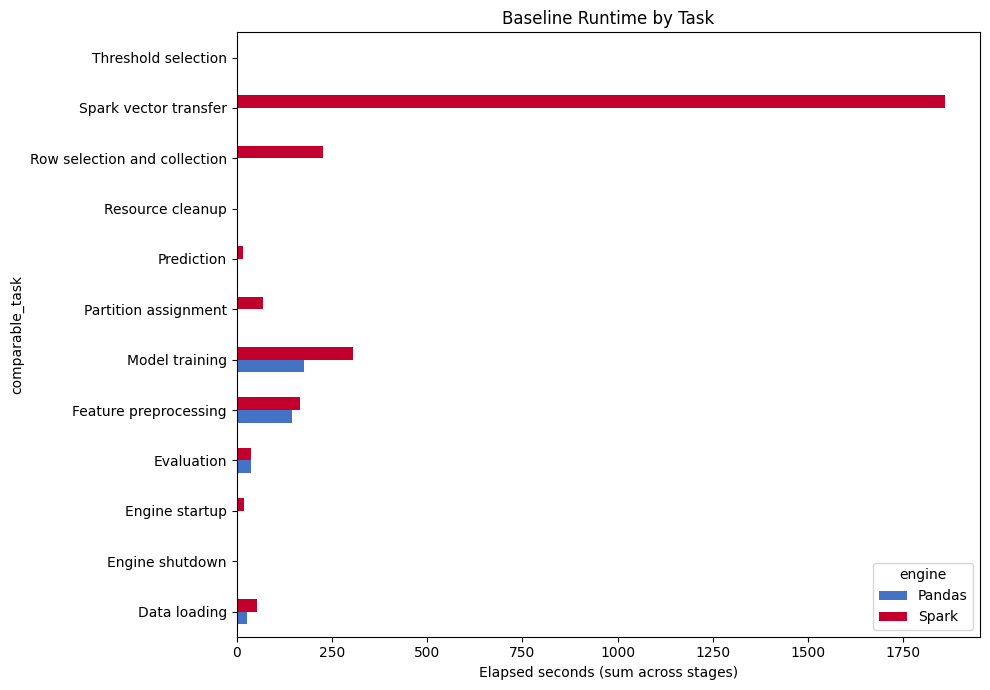

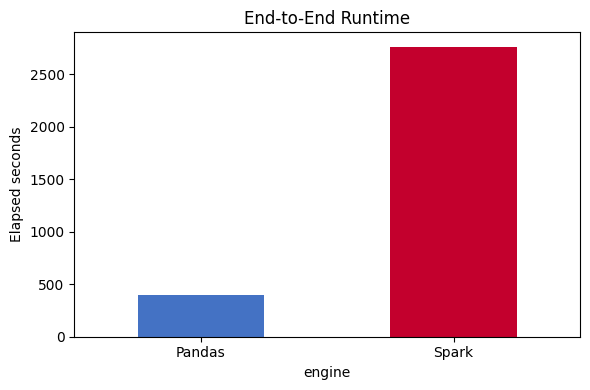

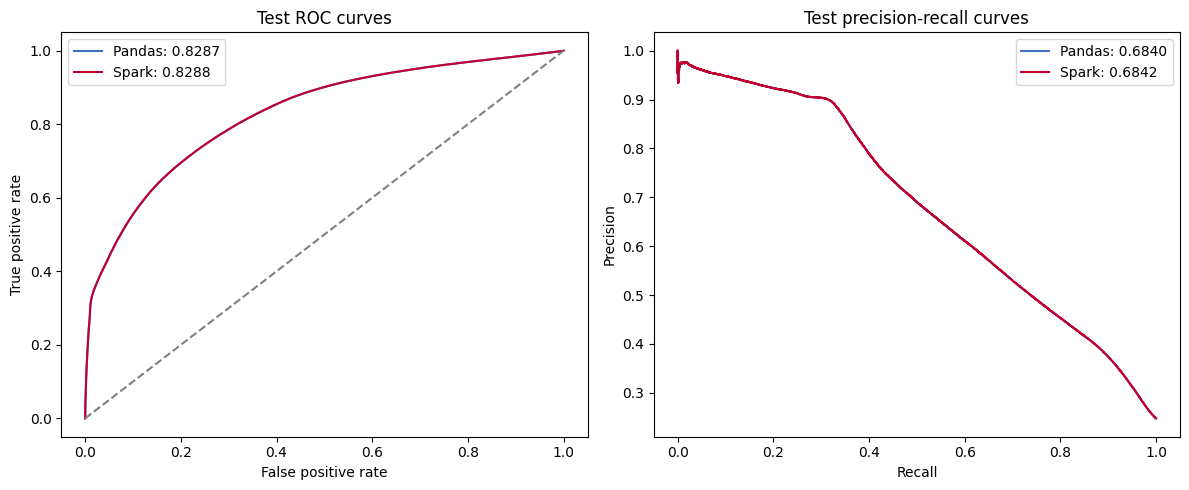

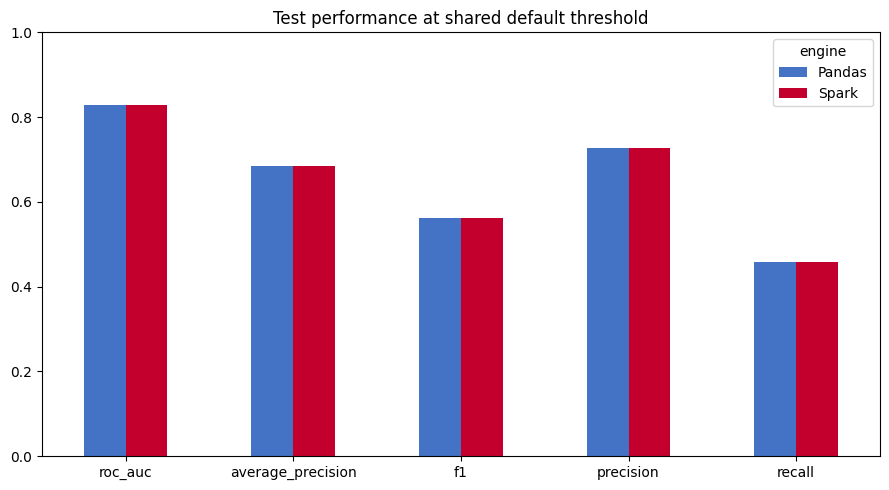

,source,roc_auc,average_precision,default_f1,optimized_f1,optimized_threshold
0,Original LR1.5 output,0.828668,0.683993,0.56206,0.606476,0.322416


Outputs: /content/drive/MyDrive/hmda/rq4_baseline_benchmark


In [ ]:
if len(complete)==2:
    ax = task[['Pandas','Spark']].plot.barh(figsize=(10,7), color=['#4472C4','#C3002D'])
    ax.set(xlabel='Elapsed seconds (sum across stages)', title='Baseline Runtime by Task'); plt.tight_layout(); plt.savefig(OUT/'runtime_tasks.png',dpi=200); plt.show(); plt.close()
    ax = total.wall_seconds.plot.bar(figsize=(6,4), color=['#4472C4','#C3002D'], rot=0)
    ax.set(ylabel='Elapsed seconds', title='End-to-End Runtime'); plt.tight_layout(); plt.savefig(OUT/'runtime_total.png',dpi=200); plt.show(); plt.close()
    fig, axes = plt.subplots(1,2,figsize=(12,5))
    for engine,color in [('Pandas','#4472C4'),('Spark','#C3002D')]:
        fp,tp,rec,prec = curves[engine]
        row = m[(m.engine==engine)&(m.phase=='Test')&(m.threshold_type=='Default')].iloc[0]
        axes[0].plot(fp,tp,label=f"{engine}: {row.roc_auc:.4f}",color=color)
        axes[1].plot(rec,prec,label=f"{engine}: {row.average_precision:.4f}",color=color)
    axes[0].plot([0,1],[0,1],'--',color='gray')
    axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='Test ROC curves')
    axes[1].set(xlabel='Recall',ylabel='Precision',title='Test precision-recall curves')
    for ax in axes: ax.legend()
    plt.tight_layout(); plt.savefig(OUT/'test_roc_pr.png',dpi=200); plt.show(); plt.close()
    selected = m[(m.phase=='Test')&(m.threshold_type=='Default')].set_index('engine')[['roc_auc','average_precision','f1','precision','recall']].T
    ax = selected.plot.bar(figsize=(9,5),color=['#4472C4','#C3002D'],rot=0); ax.set_ylim(0,1); ax.set_title('Test performance at shared default threshold')
    plt.tight_layout(); plt.savefig(OUT/'test_metrics.png',dpi=200); plt.show(); plt.close()
    # Historical notebook outputs (not rerun timings).
    reference = pd.DataFrame([{'source':'Original LR1.5 output','roc_auc':0.828668,'average_precision':0.683993,'default_f1':0.562060,'optimized_f1':0.606476,'optimized_threshold':0.322416}])
    display(reference); reference.to_csv(OUT/'original_baseline_reference.csv',index=False)
with open(OUT/'benchmark_environment.json','w') as f:
    json.dump(dict(cpu_limit=CPU, spark_driver_memory=SPARK_DRIVER_MEMORY, python=platform.python_version(), sklearn=sklearn.__version__, pandas=pd.__version__, run_order=RUN_ORDER, dataset=str(DATA_PATH), seed=SEED, spark_version=pyspark.__version__, preprocessing='shared sklearn driver-side'),f,indent=2)
print('Outputs:', OUT)

In [ ]:
import pandas as pd
from IPython.display import display, HTML

print("=== 1. RUN-TIME SUMMARY ===")
if 'total' in globals():
    display(total.round(3))
else:
    try:
        df_total = pd.read_csv(OUT / 'runtime_total.csv', index_col='engine')
        display(df_total.round(3))
    except Exception as e:
        print("Could not load runtime_total.csv:", e)

print("\n=== 2. CROSS-VALIDATION SUMMARY ===")
if 'cv' in globals():
    display(cv.round(6))
else:
    try:
        df_cv = pd.read_csv(OUT / 'cv_summary.csv', header=[0, 1], index_col=0)
        display(df_cv.round(6))
    except Exception as e:
        print("Could not load cv_summary.csv:", e)

print("\n=== 3. TEST METRICS COMPARISON ===")
try:
    df_test_comp = pd.read_csv(OUT / 'test_metric_comparison.csv')
    display(df_test_comp.round(6))
except Exception as e:
    if 'm' in globals():
        subset = m[m.phase=='Test']
        comparison = subset.melt(id_vars=['engine','fold','threshold_type'], value_vars=scores, var_name='metric').pivot(index=['fold','threshold_type','metric'],columns='engine',values='value').reindex(columns=['Pandas','Spark'])
        comparison['difference_spark_minus_pandas'] = comparison.Spark - comparison.Pandas
        display(comparison.round(6))
    else:
        print("Could not load the test comparison results:", e)

=== 1. RUN-TIME SUMMARY ===


,wall_seconds,sum_task_seconds,unallocated_seconds,engine_lifecycle_seconds,wall_excluding_engine_lifecycle,wall_minutes
engine,,,,,,
Pandas,397.070,396.987,0.083,0.000,397.070,6.618
Spark,2761.012,2758.614,2.398,19.737,2741.274,46.017



=== 2. CROSS-VALIDATION SUMMARY ===


threshold        roc_auc           average_precision            \
            mean  std      mean       std              mean       std   
engine                                                                  
Pandas       0.5  0.0  0.808738  0.027038          0.674263  0.047572   
Spark        0.5  0.0  0.808707  0.027011          0.674238  0.047588   

        accuracy           precision            ... brier_score            \
            mean       std      mean       std  ...        mean       std   
engine                                          ...                         
Pandas  0.818376  0.019740  0.765154  0.057106  ...    0.134179  0.013907   
Spark   0.818357  0.019735  0.764811  0.057497  ...    0.134204  0.013901   

       true_negative               false_positive              false_negative  \
                mean           std           mean          std           mean   
engine                                                                          
Pandas      899341.2  34801.812851        40335.6  7723.447307       188811.0   
Spark       899235.6  34719.272642        40441.2  7824.848701       188730.0   

                     true_positive                
                 std          mean           std  
engine                                            
Pandas  30706.895195      133166.8  17542.531166  
Spark   30752.792491      133247.8  17555.182303  

[2 rows x 26 columns]


=== 3. TEST METRICS COMPARISON ===


,fold,threshold_type,metric,Pandas,Spark,difference_spark_minus_pandas
0,0,Default,accuracy,8.230830e-01,8.231280e-01,0.000045
1,0,Default,average_precision,6.839930e-01,6.841880e-01,0.000195
2,0,Default,brier_score,1.274540e-01,1.274070e-01,-0.000047
3,0,Default,f1,5.620600e-01,5.621730e-01,0.000113
4,0,Default,false_negative,2.673910e+05,2.673450e+05,-46.000000
5,0,Default,false_positive,8.507700e+04,8.503300e+04,-44.000000
6,0,Default,precision,7.266680e-01,7.268110e-01,0.000143
7,0,Default,recall,4.582540e-01,4.583480e-01,0.000093
8,0,Default,roc_auc,8.286680e-01,8.287590e-01,0.000091
9,0,Default,specificity,9.432330e-01,9.432620e-01,0.000029


In [ ]:
import pandas as pd
from IPython.display import display, HTML

print("=== FINAL TEST PERFORMANCE ===")
if 'm' in globals():
    test_perf = m[m.phase == 'Test'].pivot(index='threshold_type', columns='engine', values=['roc_auc', 'average_precision', 'f1', 'precision', 'recall'])
    display(test_perf.round(6))
else:
    print("Result variable 'm' not found in the kernel.")

print("\n=== OOF F1 THRESHOLD OPTIMISATION COMPARISON ===")
if 'threshold_rows' in globals():
    df_thresh = pd.DataFrame(threshold_rows)
    display(df_thresh.round(6))
else:
    print("Optimised threshold data not found.")

=== FINAL TEST PERFORMANCE ===


roc_auc           average_precision                  f1  \
engine            Pandas     Spark            Pandas     Spark    Pandas   
threshold_type                                                             
Default         0.828668  0.828759          0.683993  0.684188  0.562060   
Optimized       0.828668  0.828759          0.683993  0.684188  0.606476   

                         precision              recall            
engine             Spark    Pandas     Spark    Pandas     Spark  
threshold_type                                                    
Default         0.562173  0.726668  0.726811  0.458254  0.458348  
Optimized       0.607180  0.603397  0.600849  0.609588  0.613646


=== OOF F1 THRESHOLD OPTIMISATION COMPARISON ===


,engine,optimal_threshold,optimal_f1,precision,recall
0,Pandas,0.322416,0.582154,0.604532,0.561374
1,Spark,0.320333,0.582108,0.601269,0.564131


In [ ]:
import pandas as pd
from IPython.display import display, HTML

# Build the dynamic summary from variables in the kernel
try:
    # 1. Get run-time information
    pandas_wall = total.loc['Pandas', 'wall_seconds']
    spark_wall = total.loc['Spark', 'wall_seconds']
    speedup_wall = spark_wall / pandas_wall

    # 2. Get training time (from detail or timings)
    df_timings = pd.DataFrame(timings)
    pandas_train = df_timings[(df_timings.engine == 'Pandas') & (df_timings.task == 'Model training')].seconds.sum()
    spark_train = df_timings[(df_timings.engine == 'Spark') & (df_timings.task == 'Model training')].seconds.sum()
    speedup_train = spark_train / pandas_train

    # 3. Largest Spark bottleneck
    spark_vector_transfer = df_timings[(df_timings.engine == 'Spark') & (df_timings.task == 'Spark vector transfer')].seconds.sum()
    spark_vector_pct = (spark_vector_transfer / spark_wall) * 100

    # 4. Get test-set metrics
    test_df = m[m.phase == 'Test']

    pandas_roc = test_df[(test_df.engine == 'Pandas') & (test_df.threshold_type == 'Default')]['roc_auc'].values[0]
    spark_roc = test_df[(test_df.engine == 'Spark') & (test_df.threshold_type == 'Default')]['roc_auc'].values[0]
    roc_diff = abs(spark_roc - pandas_roc)

    pandas_f1_def = test_df[(test_df.engine == 'Pandas') & (test_df.threshold_type == 'Default')]['f1'].values[0]
    spark_f1_def = test_df[(test_df.engine == 'Spark') & (test_df.threshold_type == 'Default')]['f1'].values[0]

    pandas_f1_opt = test_df[(test_df.engine == 'Pandas') & (test_df.threshold_type == 'Optimized')]['f1'].values[0]
    spark_f1_opt = test_df[(test_df.engine == 'Spark') & (test_df.threshold_type == 'Optimized')]['f1'].values[0]
    f1_improvement = ((pandas_f1_opt - pandas_f1_def) / pandas_f1_def) * 100

    # 5. Optimised threshold
    pandas_thresh = threshold_rows[0]['optimal_threshold']
    spark_thresh = threshold_rows[1]['optimal_threshold']

    # Create the dynamic summary DataFrame
    summary_data = {
        "Metric": [
            "Total run time",
            "Training time",
            "Largest bottleneck",
            "ROC AUC",
            "F1-score (default threshold 0.5)",
            "F1-score (optimised threshold)",
            "Threshold maximising F1"
        ],
        "Pandas (Scikit-Learn)": [
            f"{pandas_wall/60:.2f} min ({pandas_wall:.2f}s)",
            f"{pandas_train:.2f} s",
            "None",
            f"{pandas_roc:.6f}",
            f"{pandas_f1_def:.6f}",
            f"{pandas_f1_opt:.6f}",
            f"{pandas_thresh:.6f}"
        ],
        "Spark (MLlib)": [
            f"{spark_wall/60:.2f} min ({spark_wall:.2f}s)",
            f"{spark_train:.2f} s",
            f"Vector transfer ({spark_vector_transfer:.2f}s)",
            f"{spark_roc:.6f}",
            f"{spark_f1_def:.6f}",
            f"{spark_f1_opt:.6f}",
            f"{spark_thresh:.6f}"
        ],
        "Quick assessment": [
            f"Pandas ~{speedup_wall:.1f}× faster",
            f"Pandas ~{speedup_train:.1f}× faster",
            f"{spark_vector_pct:.1f}% of Spark run time",
            f"Negligible difference (~{roc_diff:.6f})",
            "Effectively identical",
            f"~{f1_improvement:.1f}% gain from threshold optimisation",
            "Nearly identical"
        ]
    }

    df_summary = pd.DataFrame(summary_data)
    display(HTML("<h3>DYNAMIC SUMMARY COMPARISON (PANDAS VS SPARK)</h3>"))
    display(df_summary)

except Exception as e:
    print("Error extracting dynamic data:", e)
    print("Make sure the variables 'total', 'timings', 'm' and 'threshold_rows' have been created first.")

,Metric,Pandas (Scikit-Learn),Spark (MLlib),Quick assessment
0,Total run time,6.62 min (397.07s),46.02 min (2761.01s),Pandas ~7.0× faster
1,Training time,177.73 s,305.53 s,Pandas ~1.7× faster
2,Largest bottleneck,None,Vector transfer (1858.48s),67.3% of Spark run time
3,ROC AUC,0.828668,0.828759,Negligible difference (~0.000091)
4,F1-score (default threshold 0.5),0.562060,0.562173,Effectively identical
5,F1-score (optimised threshold),0.606476,0.607180,~7.9% gain from threshold optimisation
6,Threshold maximising F1,0.322416,0.320333,Nearly identical
